# TPE conjunto A5b/A5 (BCI IV-4): Colab desde VS Code

Optimización conjunta con **Optuna TPE** de A5b y A5 (arquitectura, `kernel_size`, `encoder_levels`, `base_filters`, LR y L2) sobre el pipeline **P0** de las ablaciones. Especificación: `docs/plan_implementacion_TPE_ECoG.md`.

- **Búsqueda:** un estudio por sujeto, **32 trials COMPLETE** × 5 folds; los 10 primeros son los warmups equilibrados del plan (§6.1).
- **Entrenamiento:** Adam + L2, early stopping sobre el Pearson de validación (`min_delta=0`, paciencia 10 desde la época 16, máximo 50) y mejor checkpoint.
- **Verificación:** mejor trial de A5b y de A5 por sujeto × 2 semillas nuevas × 5 folds.
- **Test oficial (sección 12):** esos dos finalistas × 3 semillas, entrenados con B1–B4 y early stopping sobre B5 (máximo 70 épocas), con una sola predicción del test.
- **Test con B1–B5 (sección 13):** los mismos modelos entrenados con los cinco bloques y épocas fijas (mediana de las `best_epoch` de verificación), comparados de forma apareada con la sección 12.
- **Retardo:** ECoG(t) → guante(t + **20 ms**) = 2 columnas a 100 Hz, como en las ablaciones.
- La búsqueda y la verificación no guardan pesos (cada fold conserva métricas y `predictions.npz` del mejor checkpoint); solo los modelos de test guardan `model.pt`.

Este notebook se abre en **VS Code** y se ejecuta en un **servidor de Colab** con la extensión *Google Colab*: las celdas corren en la máquina remota (`/content/...`), no en tu PC.

**Preparación (una vez)**
1. Instala la extensión *Google Colab* en VS Code e inicia sesión con tu cuenta de Google.
2. Los `.mat` pueden ser los mismos de las ablaciones (`DATA_DIR`).
3. Haz `git push` de este repositorio a GitHub, idealmente con una etiqueta fija para la campaña (`GIT_REF`).

**Importante**
- **El código viene del commit clonado en el servidor**, no de tu carpeta local. Si cambias `src/`, haz commit y push y reejecuta la celda 3.
- Mantén VS Code conectado. Si el servidor se recicla, los resultados están en Drive: abre un servidor nuevo, ejecuta las celdas 1–3 y vuelve a lanzar la 7 (o la 10, la 12 o la 13). El estudio se reanuda desde `results/studies/<S>_study.zip`; el trial que estaba en curso se repite con los mismos parámetros.
- **Un runtime por sujeto** si quieres paralelizar: cada servidor con `SUBJECTS` disjuntos sobre el mismo `RESULTS_DIR`. Nunca dos procesos sobre el mismo sujeto.
- Usa la **misma clase de GPU** en toda la campaña: TF32 cambia ligeramente la aritmética entre GPUs.

## 1. GPU y Google Drive
Si `drive.mount` no lanza el inicio de sesión, usa el comando de VS Code *Colab: Mount Google Drive to Server...*.

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
from google.colab import drive
drive.mount("/content/drive")

name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Configuración

In [2]:
GIT_URL = "https://github.com/SaulRodas/TPE_ECoG.git"   # ← tu repositorio ("" = código subido a mano)
GIT_REF = "main"           # recomendado: una etiqueta fija para toda la campaña, p. ej. "tpe-v1"
PRIVATE_REPO = False       # True → la celda 3 pide un token de GitHub de solo lectura
REPO_DIR = "/content/TPE_ECoG"   # carpeta del código EN EL SERVIDOR

DRIVE_ROOT = "/content/drive/MyDrive"
DATA_DIR = f"{DRIVE_ROOT}/ECoG_Architectures_Exploration/data/raw"   # mismos .mat que las ablaciones
TEST_LABELS_DIR = f"{DRIVE_ROOT}/TPE_ECoG/test_labels"   # sub{1,2,3}_testlabels.mat (solo la sección 12)
RESULTS_DIR = f"{DRIVE_ROOT}/TPE_ECoG/results"
WORK_DIR = "/content/tpe_work"     # disco local del servidor: SQLite de trabajo (se publica en Drive tras cada trial)

SUBJECTS = ["S1", "S2", "S3"]      # un runtime por sujeto para paralelizar, p. ej. ["S2"]

import os
missing = [f for f in ("sub1_comp.mat", "sub2_comp.mat", "sub3_comp.mat") if not os.path.exists(f"{DATA_DIR}/{f}")]
print("datos OK" if not missing else f"faltan en {DATA_DIR}: {missing}")
os.makedirs(RESULTS_DIR, exist_ok=True)

datos OK


## 3. Código y dependencias en el servidor
- **Opción A (recomendada):** se clona `GIT_URL` en `GIT_REF`; el commit queda registrado en cada trial.
- **Opción B:** con `GIT_URL = ""`, sube `src`, `scripts`, `configs`, `tests`, `reference` y `pyproject.toml` con clic derecho → *Upload to Colab* y pon `REPO_DIR = "/content"`.

Solo se instalan `mne` y `optuna==5.0.0` (lo demás viene en Colab).

In [3]:
import base64, getpass, subprocess, sys

TOKEN = getpass.getpass("Token de GitHub (solo lectura): ") if (GIT_URL and PRIVATE_REPO) else None

def git(*args, cwd=None):
    cmd = ["git"]
    if TOKEN:
        basic = base64.b64encode(f"x-access-token:{TOKEN}".encode()).decode()
        cmd += ["-c", f"http.extraHeader=Authorization: Basic {basic}"]
    out = subprocess.run(cmd + list(args), cwd=cwd, capture_output=True, text=True)
    if out.returncode != 0:
        message = out.stderr.replace(TOKEN, "***") if TOKEN else out.stderr
        raise RuntimeError(f"git {args[0]} falló: {message[-800:]}")
    return out.stdout.strip()

if GIT_URL:
    if not os.path.exists(f"{REPO_DIR}/.git"):
        git("clone", "--quiet", GIT_URL, REPO_DIR)
    git("fetch", "--quiet", "--tags", "origin", cwd=REPO_DIR)
    git("checkout", "--quiet", GIT_REF, cwd=REPO_DIR)
    if git("rev-parse", "--abbrev-ref", "HEAD", cwd=REPO_DIR) != "HEAD":   # rama (no etiqueta): actualizar
        git("pull", "--quiet", "--ff-only", cwd=REPO_DIR)
    print("commit:", git("log", "-1", "--format=%h %s (%ci)", cwd=REPO_DIR))
else:
    assert os.path.exists(f"{REPO_DIR}/src/ecog_tpe"), f"no está el código en {REPO_DIR} (¿Upload to Colab?)"
    print("usando código subido en", REPO_DIR)

!pip install -q "mne>=1.6" "optuna==5.0.0"

sys.path.insert(0, f"{REPO_DIR}/src")
from ecog_tpe.config import load_config
from ecog_tpe import reporting
CFG = load_config(f"{REPO_DIR}/configs/tpe.yaml")
print("configuración:", CFG["_path"])
print("retardo", CFG["preprocessing"]["delay_ms"], "ms =", CFG["_derived"]["delay_columns"], "columnas | TF32",
      CFG["runtime"]["allow_tf32"], "| early stopping", CFG["training"]["early_stopping"])

commit: b771a1f Tests (2026-10-30 15:31:29 -0600)
configuración: /content/TPE_ECoG/configs/tpe.yaml
retardo 20 ms = 2 columnas | TF32 True | early stopping {'min_delta': 0.0, 'patience': 10, 'min_epochs': 15, 'max_epochs': 50}


## 4. Comprobaciones mínimas (`pytest`)
Pipeline P0 (datos reales, fugas, retardo de 2 columnas, DSP frente a MNE), las 16 combinaciones de A5b/A5, la política de parada (incluida la tabla 1.1 del plan sobre los históricos de las ablaciones), `train_fold` y el estudio Optuna con un runner simulado (warmups, reanudación, fallos, verificación y reportes).

In [4]:
!cd "{REPO_DIR}" && ECOG_DATA_DIR="{DATA_DIR}" python -m pytest -q -p no:cacheprovider 2>&1 | tail -5

.......................................................                  [100%]
55 passed in 82.45s (0:01:22)


## 5. Capacidad de la GPU (plan §3.2)
Forward/backward + paso de Adam con batch 128 en las **16 combinaciones** discretas, con el sujeto de más canales (S3) y un tensor del tamaño de X del fold en la GPU. **Si alguna da OOM, hay que ajustar el espacio antes del primer estudio** (no se permite cambiar batch ni precisión por trial). La estimación de horas usa 32.3 épocas por fold (media retrospectiva) y es solo orientativa.

In [5]:
!cd "{REPO_DIR}" && python scripts/run_tpe.py --capacity --results-dir "{RESULTS_DIR}" 2>&1 | grep -v Warning | tail -24

2026-10-29 23:18:41 INFO capacidad A5 k5 L5 f64: ok
2026-10-29 23:18:42 INFO capacidad A5 k5 L5 f96: ok
2026-10-29 23:18:42 INFO capacidad A5 k7 L4 f64: ok
2026-10-29 23:18:42 INFO capacidad A5 k7 L4 f96: ok
2026-10-29 23:18:43 INFO capacidad A5 k7 L5 f64: ok
2026-10-29 23:18:43 INFO capacidad A5 k7 L5 f96: ok
architecture_id  kernel_size  encoder_levels  base_filters         label status  n_parameters  seconds_per_step  est_epoch_seconds  peak_memory_gb
            A5b            5               4            64 A5b k5 L4 f64     ok       5427909            0.0261             6.0212          1.1304
            A5b            5               4            96 A5b k5 L4 f96     ok      11846693            0.0357             8.2394          1.4045
            A5b            5               5            64 A5b k5 L5 f64     ok       9362117            0.0254             5.8554          1.2161
            A5b            5               5            96 A5b k5 L5 f96     ok      20697125       

## 6. Smoke real (S1/B1, warmups del par 1, 2 épocas × 2 batches)
Recorre la cadena completa con datos reales en `RESULTS_DIR/_smoke` (separado de la campaña; se borra en cada smoke): características P0, estudio, warmups, objetivo, publicación del zip y reporte.

In [6]:
!cd "{REPO_DIR}" && python scripts/run_tpe.py --smoke --results-dir "{RESULTS_DIR}" --work-dir "{WORK_DIR}" 2>&1 | grep -v Warning | tail -20

import glob, json
import pandas as pd
from IPython.display import display
rows = []
for path in sorted(glob.glob(f"{RESULTS_DIR}/_smoke/trials/S1/trial_*/B1/history.csv")):
    h = pd.read_csv(path)
    config = json.load(open(path.replace("B1/history.csv", "config.json"), encoding="utf-8"))
    rows.append({"trial": path.split("/")[-3], "arquitectura": config["label"],
                 "s_por_batch": (h.train_seconds / h.n_batches).iloc[-1], "s_validación": h.val_seconds.iloc[-1]})
display(pd.DataFrame(rows).round(4))
!cd "{REPO_DIR}" && python scripts/report_tpe.py --results-dir "{RESULTS_DIR}/_smoke" 2>&1 | tail -12

  File "/content/TPE_ECoG/src/ecog_tpe/runs.py", line 250, in fold
    raw = load_subject(self.data_dir, self.subject, self.cfg)
  File "/content/TPE_ECoG/src/ecog_tpe/data.py", line 25, in load_subject
    raise FileNotFoundError(f"no se encontró {path}")
FileNotFoundError: no se encontró /content/TPE_ECoG/data/raw/sub1_comp.mat
[W 2026-10-29 23:18:54,651] Trial 2 failed with value None.
2026-10-29 23:18:54 ERROR [S1 t002] FAIL: FileNotFoundError: no se encontró /content/TPE_ECoG/data/raw/sub1_comp.mat
Traceback (most recent call last):
  File "/content/TPE_ECoG/scripts/run_tpe.py", line 99, in <module>
    sys.exit(main())
             ~~~~^^
  File "/content/TPE_ECoG/scripts/run_tpe.py", line 77, in main
    info = run_smoke(cfg, data_dir, results_dir, args.device, args.work_dir, subjects[0] if subjects else None)
  File "/content/TPE_ECoG/src/ecog_tpe/search.py", line 374, in run_smoke
    return run_search(cfg, subject or list(cfg["data"]["subjects"])[0], data_dir, smoke_dir, devi

""


Ablaciones con la política de parada simulada (plan §1.1; media de las curvas sujeto-fold):
                 pearson_epoch50  pearson_es  pearson_best50  diff_es_minus_best50  epochs_trained_es
architecture_id                                                                                      
A5                      0.683715    0.733021        0.736028             -0.003007               30.6
A5b                     0.677915    0.711371        0.714723             -0.003352               34.0
ambas                   0.680815    0.722196        0.725376             -0.003180               32.3

Pearson macro global (media de sujetos con igual peso):
architecture_id       A5     A5b
source                          
ablation_epoch50  0.6837  0.6779
ablation_es_sim   0.7330  0.7114


## 7. Lanzar la búsqueda en segundo plano
Un proceso independiente recorre `SUBJECTS` en orden, cada uno hasta 32 trials COMPLETE (reanudable). El log queda en `RESULTS_DIR/logs/`. Si ya hay un runner vivo en este servidor, el nuevo se niega a arrancar.

In [7]:
import subprocess, sys, time
os.makedirs(f"{RESULTS_DIR}/logs", exist_ok=True)
LOG_PATH = f"{RESULTS_DIR}/logs/tpe_{'_'.join(SUBJECTS)}_{time.strftime('%Y%m%d_%H%M%S')}.log"
args = [sys.executable, "-u", f"{REPO_DIR}/scripts/run_tpe.py", "--subjects", *SUBJECTS,
        "--data-dir", DATA_DIR, "--results-dir", RESULTS_DIR, "--work-dir", WORK_DIR]
PROC = subprocess.Popen(args, stdout=open(LOG_PATH, "a"), stderr=subprocess.STDOUT, cwd=REPO_DIR,
                        start_new_session=True)
time.sleep(30)
print("PID", PROC.pid, "| estado:", "en marcha" if PROC.poll() is None else f"terminó (código {PROC.returncode})")
print("log:", LOG_PATH, "  (en la terminal de Colab: tail -f", LOG_PATH + ")")
print(open(LOG_PATH).read()[-2000:])

PID 6433 | estado: en marcha
log: /content/drive/MyDrive/TPE_ECoG/results/logs/tpe_S1_S2_S3_20261029_231901.log   (en la terminal de Colab: tail -f /content/drive/MyDrive/TPE_ECoG/results/logs/tpe_S1_S2_S3_20261029_231901.log)
2026-10-29 23:19:02 INFO NumExpr defaulting to 12 threads.
2026-10-29 23:19:07 INFO [S1] estudio joint_tpe_S1: 32/32 trials COMPLETE, 0 en cola; sampler restaurado; dispositivo cuda
2026-10-29 23:19:07 INFO [S1] estudio completo: 32 trials COMPLETE; mejor objetivo 0.7117 (trial 10, A5 k5 L5 f64)
2026-10-29 23:19:08 INFO [S2] estudio joint_tpe_S2: 32/32 trials COMPLETE, 0 en cola; sampler restaurado; dispositivo cuda
2026-10-29 23:19:08 INFO [S2] estudio completo: 32 trials COMPLETE; mejor objetivo 0.6878 (trial 30, A5 k7 L5 f96)
2026-10-29 23:19:10 INFO [S3] estudio joint_tpe_S3: 0/32 trials COMPLETE, 10 en cola; sampler restaurado; dispositivo cuda
2026-10-29 23:19:10 WARNING intento previo de trial_000 archivado en /content/drive/MyDrive/TPE_ECoG/results/trials

## 8. Monitor (reejecutable)
Progreso por sujeto (COMPLETE/FAIL de 32, mejor objetivo por arquitectura, ETA), trial y fold en curso con su curva en vivo, latido del runner y últimas líneas del log. **Detener esta celda (■) no detiene el entrenamiento.**

In [ ]:
reporting.monitor(RESULTS_DIR, CFG, SUBJECTS, refresh=30)

2026-10-30 05:56:28
runner 5cd20d5b8846-5513: último latido hace 39715 s · [S3 t000] B2
S1: COMPLETE 32/32 · FAIL 0 · mejor A5 0.7117 (t10) · A5b 0.6618 (t24) · ETA 0 h 00 min
S2: COMPLETE 32/32 · FAIL 0 · mejor A5 0.6878 (t30) · A5b 0.6480 (t0) · ETA 0 h 00 min
S3: COMPLETE 32/32 · FAIL 0 · mejor A5 0.8533 (t26) · A5b 0.8380 (t22) · ETA 0 h 00 min
— últimas líneas de tpe_S1_S2_S3_20261029_231901.log —
2026-10-30 05:54:56 INFO [S3 t031] B5 época 33/50  train 0.0013  val 0.0257  r_val 0.7968  mejor 0.8077 (ép. 29)  espera 4  (3.2 s)
2026-10-30 05:54:59 INFO [S3 t031] B5 época 34/50  train 0.0013  val 0.0265  r_val 0.8004  mejor 0.8077 (ép. 29)  espera 5  (3.2 s)
2026-10-30 05:55:02 INFO [S3 t031] B5 época 35/50  train 0.0013  val 0.0272  r_val 0.7955  mejor 0.8077 (ép. 29)  espera 6  (3.2 s)
2026-10-30 05:55:05 INFO [S3 t031] B5 época 36/50  train 0.0012  val 0.0272  r_val 0.7977  mejor 0.8077 (ép. 29)  espera 7  (3.2 s)
2026-10-30 05:55:09 INFO [S3 t031] B5 época 37/50  train 0.0012  v

: 

## 9. Detener
Envía SIGINT al runner de este servidor: el trial en curso no se publica y se repetirá (con los mismos parámetros) al relanzar la celda 7, la 10, la 12 o la 13.

In [5]:
import glob, json, signal, socket
for path in glob.glob(f"{RESULTS_DIR}/runners/{socket.gethostname()}-*.json"):
    pid = json.load(open(path))["pid"]
    try:
        os.killpg(os.getpgid(pid), signal.SIGINT)
        print("SIGINT enviado al runner", pid)
    except ProcessLookupError:
        print("el runner", pid, "ya no existe")

## 10. Verificación de finalistas (plan §7)
Cuando un sujeto tiene **32 trials COMPLETE**: su mejor trial de A5b y de A5 se reentrenan con las semillas 1042 y 2042 (+ 5·sujeto + fold) en los cinco folds, con la misma política. La elección queda en `verification/<S>/finalists.json` y no se recalcula al reanudar. Se detiene con la sección 9.

In [6]:
import json, zipfile
import os, time
for s in SUBJECTS:
    path = f"{RESULTS_DIR}/studies/{s}_study.zip"
    meta = json.loads(zipfile.ZipFile(path).read("meta.json")) if os.path.exists(path) else {}
    print(s, "COMPLETE:", meta.get("n_complete", 0), "/", CFG["search"]["n_trials_per_subject"])

LOG_PATH = f"{RESULTS_DIR}/logs/verify_{'_'.join(SUBJECTS)}_{time.strftime('%Y%m%d_%H%M%S')}.log"
args = [sys.executable, "-u", f"{REPO_DIR}/scripts/run_tpe.py", "--subjects", *SUBJECTS, "--verify",
        "--data-dir", DATA_DIR, "--results-dir", RESULTS_DIR]
PROC = subprocess.Popen(args, stdout=open(LOG_PATH, "a"), stderr=subprocess.STDOUT, cwd=REPO_DIR,
                        start_new_session=True)
time.sleep(30)
print("PID", PROC.pid, "| estado:", "en marcha" if PROC.poll() is None else f"terminó (código {PROC.returncode})")
print(open(LOG_PATH).read()[-2000:])

S1 COMPLETE: 32 / 32
S2 COMPLETE: 32 / 32
S3 COMPLETE: 32 / 32
PID 2610 | estado: en marcha
2026-10-30 17:35:42 INFO NumExpr defaulting to 12 threads.
2026-10-30 17:35:49 INFO [S1 verif] A5b: trial 24 (A5b k5 L5 f64), objetivo de búsqueda 0.6618
2026-10-30 17:35:52 INFO [S1 verif] A5: trial 10 (A5 k5 L5 f64), objetivo de búsqueda 0.7117
2026-10-30 17:35:55 INFO [S1] verificación completa
2026-10-30 17:35:55 INFO [S2 verif] A5b: trial 0 (A5b k5 L5 f64), objetivo de búsqueda 0.6480
2026-10-30 17:35:58 INFO [S2 verif] A5: trial 30 (A5 k7 L5 f96), objetivo de búsqueda 0.6878
2026-10-30 17:36:02 WARNING intento previo de B4 archivado en /content/drive/MyDrive/TPE_ECoG/results/verification/S2/A5/seed_2042/_attempts/B4_20261030-173602



In [ ]:
# Apagado automático: ejecútala EN LUGAR del monitor, después de lanzar la sección 7, 10, 12 o 13.
# Espera a que termine el runner de este servidor. Si era la búsqueda y todos los SUBJECTS tienen 32 COMPLETE,
# lanza la verificación (sección 10) y la espera también; con CHAIN_TEST, después el test (sección 12), y con
# CHAIN_TEST_FULL, el test con B1–B5 (sección 13).
# Luego genera el reporte, sincroniza Drive y libera el servidor.
# ■ cancela solo el apagado (el entrenamiento sigue); si el clic cae dentro del monitor, púlsalo otra vez.
import glob, json, os, socket, subprocess, sys, time, zipfile
from google.colab import drive, runtime
from ecog_tpe.runs import read_json

CHAIN_VERIFICATION = True   # False → solo espera al runner actual y apaga
CHAIN_TEST = False          # True → al terminar la verificación lanza también el test (sección 12)
CHAIN_TEST_FULL = False     # True → después (de la verificación o del test) lanza el test con B1–B5 (sección 13)
REFRESH = 60                # segundos entre comprobaciones

def live_runners():
    alive = []
    for path in glob.glob(f"{RESULTS_DIR}/runners/{socket.gethostname()}-*.json"):
        info = read_json(path) or {}
        try:  # un hijo del kernel que ya terminó sigue en /proc como zombi (estado Z)
            state = open(f"/proc/{info['pid']}/stat").read().rsplit(")", 1)[1].split()[0]
        except (KeyError, FileNotFoundError):
            continue
        if state != "Z":
            alive.append(info)
    return alive

def wait_runners():
    """Bloquea hasta que no quede ningún runner vivo; devuelve el tipo del último: search, verify, test o
    test_full."""
    kind = None
    while runners := live_runners():
        argv = runners[0].get("argv", [])
        kind = ("test_full" if "--test-full" in argv else "test" if "--test" in argv
                else "verify" if "--verify" in argv else "search")
        reporting.monitor(RESULTS_DIR, CFG, SUBJECTS, max_updates=1, verification=kind == "verify",
                          final_test=kind in ("test", "test_full"),
                          protocols=["b1b5_fixed"] if kind == "test_full" else ["b1b4_es_b5"])
        time.sleep(REFRESH)
    return kind

def launch(flag, name, *extra):
    """Lanza run_tpe.py con ``flag`` en segundo plano (como las secciones 10 y 12) y espera a que termine."""
    global PROC, LOG_PATH
    LOG_PATH = f"{RESULTS_DIR}/logs/{name}_{'_'.join(SUBJECTS)}_{time.strftime('%Y%m%d_%H%M%S')}.log"
    args = [sys.executable, "-u", f"{REPO_DIR}/scripts/run_tpe.py", "--subjects", *SUBJECTS, flag,
            "--data-dir", DATA_DIR, "--results-dir", RESULTS_DIR, *extra]
    PROC = subprocess.Popen(args, stdout=open(LOG_PATH, "a"), stderr=subprocess.STDOUT, cwd=REPO_DIR,
                            start_new_session=True)
    while PROC.poll() is None and not live_runners():  # hasta que tome el lock (o muera al arrancar)
        time.sleep(5)
    return wait_runners()

assert live_runners(), "no hay ningún runner vivo en este servidor: lanza antes la sección 7, 10, 12 o 13"
try:
    kind = wait_runners()
    if kind == "search" and CHAIN_VERIFICATION:
        complete = {}
        for s in SUBJECTS:
            path = f"{RESULTS_DIR}/studies/{s}_study.zip"
            complete[s] = json.loads(zipfile.ZipFile(path).read("meta.json"))["n_complete"] if os.path.exists(path) else 0
        if all(n >= CFG["search"]["n_trials_per_subject"] for n in complete.values()):
            kind = launch("--verify", "verify")
        else:
            print("búsqueda incompleta, no se lanza la verificación:", complete)
    if kind == "verify" and CHAIN_TEST:
        kind = launch("--test", "test", "--test-labels-dir", TEST_LABELS_DIR)
    if kind in ("verify", "test") and CHAIN_TEST_FULL:
        kind = launch("--test-full", "test_full", "--test-labels-dir", TEST_LABELS_DIR)
except KeyboardInterrupt:
    print("apagado automático cancelado (el entrenamiento en segundo plano sigue)")
else:
    try:
        rep = subprocess.run([sys.executable, f"{REPO_DIR}/scripts/report_tpe.py", "--results-dir", RESULTS_DIR],
                             cwd=REPO_DIR, capture_output=True, text=True, timeout=1800)
        print(rep.stdout[-1500:])
    except subprocess.TimeoutExpired:
        print("el reporte tardó más de 30 min; se omite (ejecuta la sección 11 en otra sesión)")
    try:
        drive.flush_and_unmount()
        print("Drive sincronizado")
    except Exception as exc:  # p. ej. si Drive se montó desde el comando de la extensión
        print("flush_and_unmount falló:", exc, "→ espero 3 min a que Drive suba lo pendiente")
        os.sync()
        time.sleep(180)
    print(time.strftime("%H:%M:%S"), "liberando el servidor…")
    try:
        runtime.unassign()
    except Exception as exc:
        print("runtime.unassign() falló:", exc)
    time.sleep(120)
    print("⚠ el servidor sigue asignado: libéralo a mano con «Colab: Remove Server»")


2026-10-30 18:43:26
runner 5aab059852bf-104772: último latido hace 38787 s · [S2 verif A5 s2042 B4]
runner 5cd20d5b8846-5513: último latido hace 85732 s · [S3 t000] B2
runner 65457eb9baaa-2610: último latido hace 1 s · [S3 verif A5 s2042 B5]
S1: 20/20 corridas · media A5 0.6929 · A5b 0.6660 · en curso: 
S2: 20/20 corridas · media A5 0.6785 · A5b 0.6348 · en curso: 
S3: 19/20 corridas · media A5 0.8415 · A5b 0.8327 · en curso: A5 s2042 B5
— últimas líneas de verify_S1_S2_S3_20261030_173540.log —
2026-10-30 18:42:52 INFO [S3 verif A5 s2042 B5] época 16/50  train 0.0032  val 0.0239  r_val 0.8284  mejor 0.8284 (ép. 16)  espera 0  (3.6 s)
2026-10-30 18:42:55 INFO [S3 verif A5 s2042 B5] época 17/50  train 0.0031  val 0.0239  r_val 0.8266  mejor 0.8284 (ép. 16)  espera 1  (3.6 s)
2026-10-30 18:42:59 INFO [S3 verif A5 s2042 B5] época 18/50  train 0.0029  val 0.0238  r_val 0.8256  mejor 0.8284 (ép. 16)  espera 2  (3.6 s)
2026-10-30 18:43:03 INFO [S3 verif A5 s2042 B5] época 19/50  train 0.0028 

In [8]:
# Monitor de la verificación (reejecutable; detenerlo no detiene el entrenamiento)
reporting.monitor(RESULTS_DIR, CFG, SUBJECTS, refresh=10, verification=True)

2026-10-30 06:16:58
runner 5aab059852bf-104772: último latido hace 1 s · [S1 verif A5b s2042 B1]
runner 5cd20d5b8846-5513: último latido hace 40945 s · [S3 t000] B2
S1: 5/20 corridas · media A5b 0.6596 · en curso: A5b s2042 B1
S2: verificación sin empezar
S3: verificación sin empezar
— últimas líneas de verify_S1_S2_S3_20261030_055849.log —
2026-10-30 06:16:07 INFO [S1 verif A5b s2042 B1] época 19/50  train 0.0020  val 0.0606  r_val 0.6296  mejor 0.6327 (ép. 17)  espera 2  (5.6 s)
2026-10-30 06:16:12 INFO [S1 verif A5b s2042 B1] época 20/50  train 0.0020  val 0.0604  r_val 0.6295  mejor 0.6327 (ép. 17)  espera 3  (5.6 s)
2026-10-30 06:16:18 INFO [S1 verif A5b s2042 B1] época 21/50  train 0.0038  val 0.0614  r_val 0.6241  mejor 0.6327 (ép. 17)  espera 4  (5.6 s)
2026-10-30 06:16:24 INFO [S1 verif A5b s2042 B1] época 22/50  train 0.0021  val 0.0615  r_val 0.6194  mejor 0.6327 (ép. 17)  espera 5  (5.6 s)
2026-10-30 06:16:29 INFO [S1 verif A5b s2042 B1] época 23/50  train 0.0019  val 0.061

## 11. Reporte
Genera `RESULTS_DIR/summary/` con lo que haya (se puede ejecutar a mitad de campaña): `tpe_trials.csv`, `tpe_folds.csv`, `tpe_verification.csv`, `tpe_selected_models.csv`, la retrospectiva de las ablaciones (`ablation_retrospective.csv`, tabla 1.1) y la comparación del §10 (`tpe_comparison.csv`, por sujeto, dedo y fold). Recuerda: los mejores checkpoints son métricas de **selección sobre validación**, no rendimiento de test (el test oficial es la sección 12).

    "S1": {
      "COMPLETE": 32
    },
    "S2": {
      "COMPLETE": 32
    },
    "S3": {
      "COMPLETE": 32
    }
  },
  "verification_completed": 60,
  "figures": {
    "optimization_history": "/content/drive/MyDrive/TPE_ECoG/results/summary/figures/optimization_history.png",
    "params_vs_objective": "/content/drive/MyDrive/TPE_ECoG/results/summary/figures/params_vs_objective.png",
    "verification": "/content/drive/MyDrive/TPE_ECoG/results/summary/figures/verification.png",
    "reference_curves": "/content/drive/MyDrive/TPE_ECoG/results/summary/figures/reference_curves.png"
  }
}

Ablaciones con la política de parada simulada (plan §1.1; media de las curvas sujeto-fold):
                 pearson_epoch50  pearson_es  pearson_best50  diff_es_minus_best50  epochs_trained_es
architecture_id                                                                                      
A5                      0.683715    0.733021        0.736028             -0.003007               30.6
A5b

,subject,trial,source,label,learning_rate,weight_decay,objective_cv_best,mean_best_epoch,mean_epochs_trained
90,S3,26,tpe,A5 k7 L5 f64,0.00005,0.00000,0.85330,29.8,37.2
91,S3,27,tpe,A5 k7 L5 f64,0.00006,0.00000,0.85259,30.0,38.6
88,S3,24,tpe,A5 k7 L5 f64,0.00005,0.00000,0.84987,30.8,38.2
93,S3,29,tpe,A5 k7 L5 f64,0.00007,0.00000,0.84971,27.4,37.6
92,S3,28,tpe,A5 k7 L5 f64,0.00005,0.00001,0.84915,23.4,33.4
10,S1,10,tpe,A5 k5 L5 f64,0.00014,0.00000,0.71169,20.8,31.6
1,S1,1,warmup,A5 k5 L5 f64,0.00008,0.00000,0.71033,16.8,28.6
11,S1,11,tpe,A5 k5 L5 f64,0.00008,0.00000,0.71017,21.0,32.2
28,S1,28,tpe,A5 k5 L5 f64,0.00011,0.00000,0.71008,19.0,29.4
29,S1,29,tpe,A5 k5 L5 f96,0.00009,0.00000,0.70870,20.8,30.8


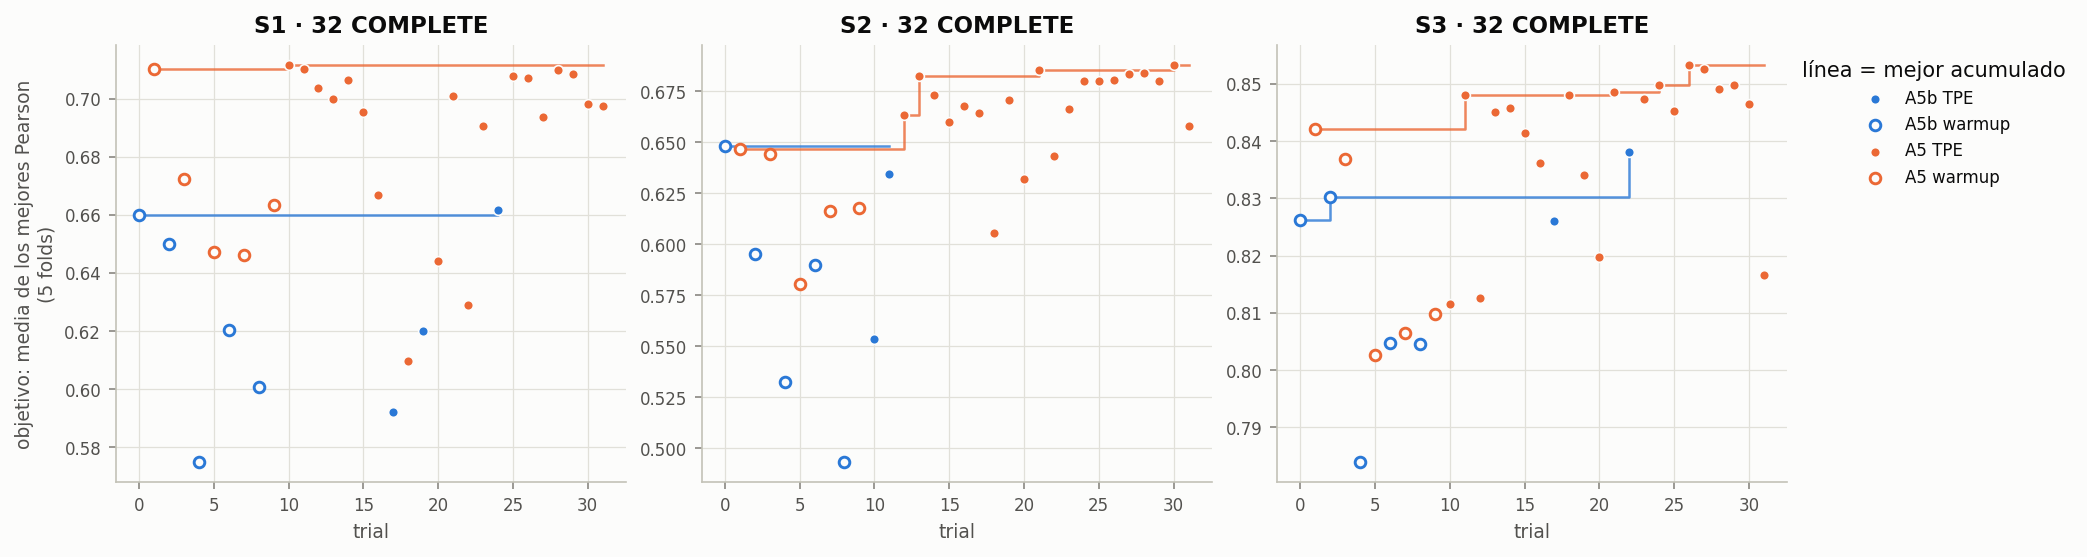

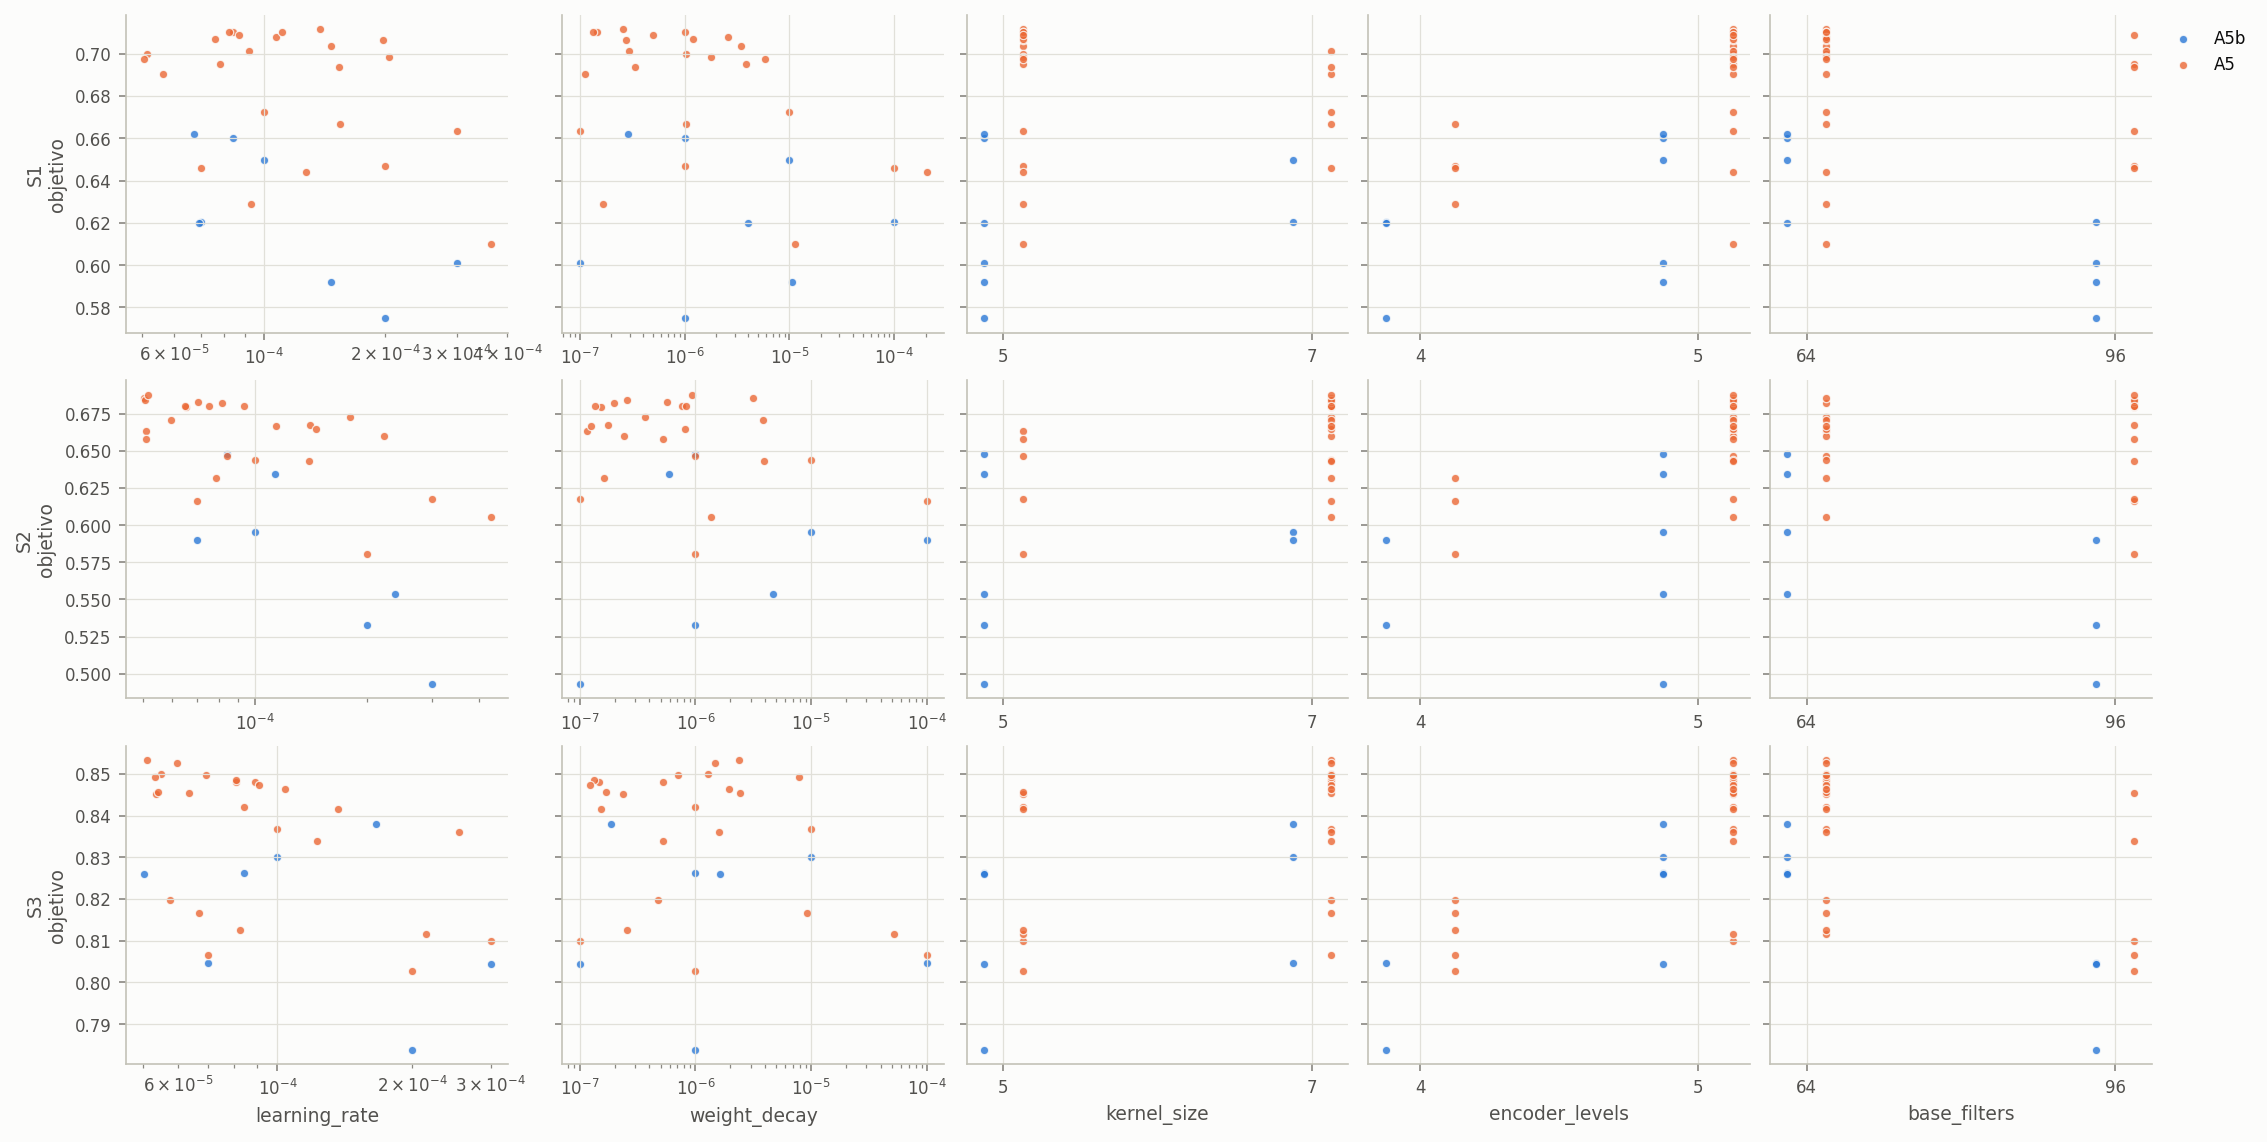

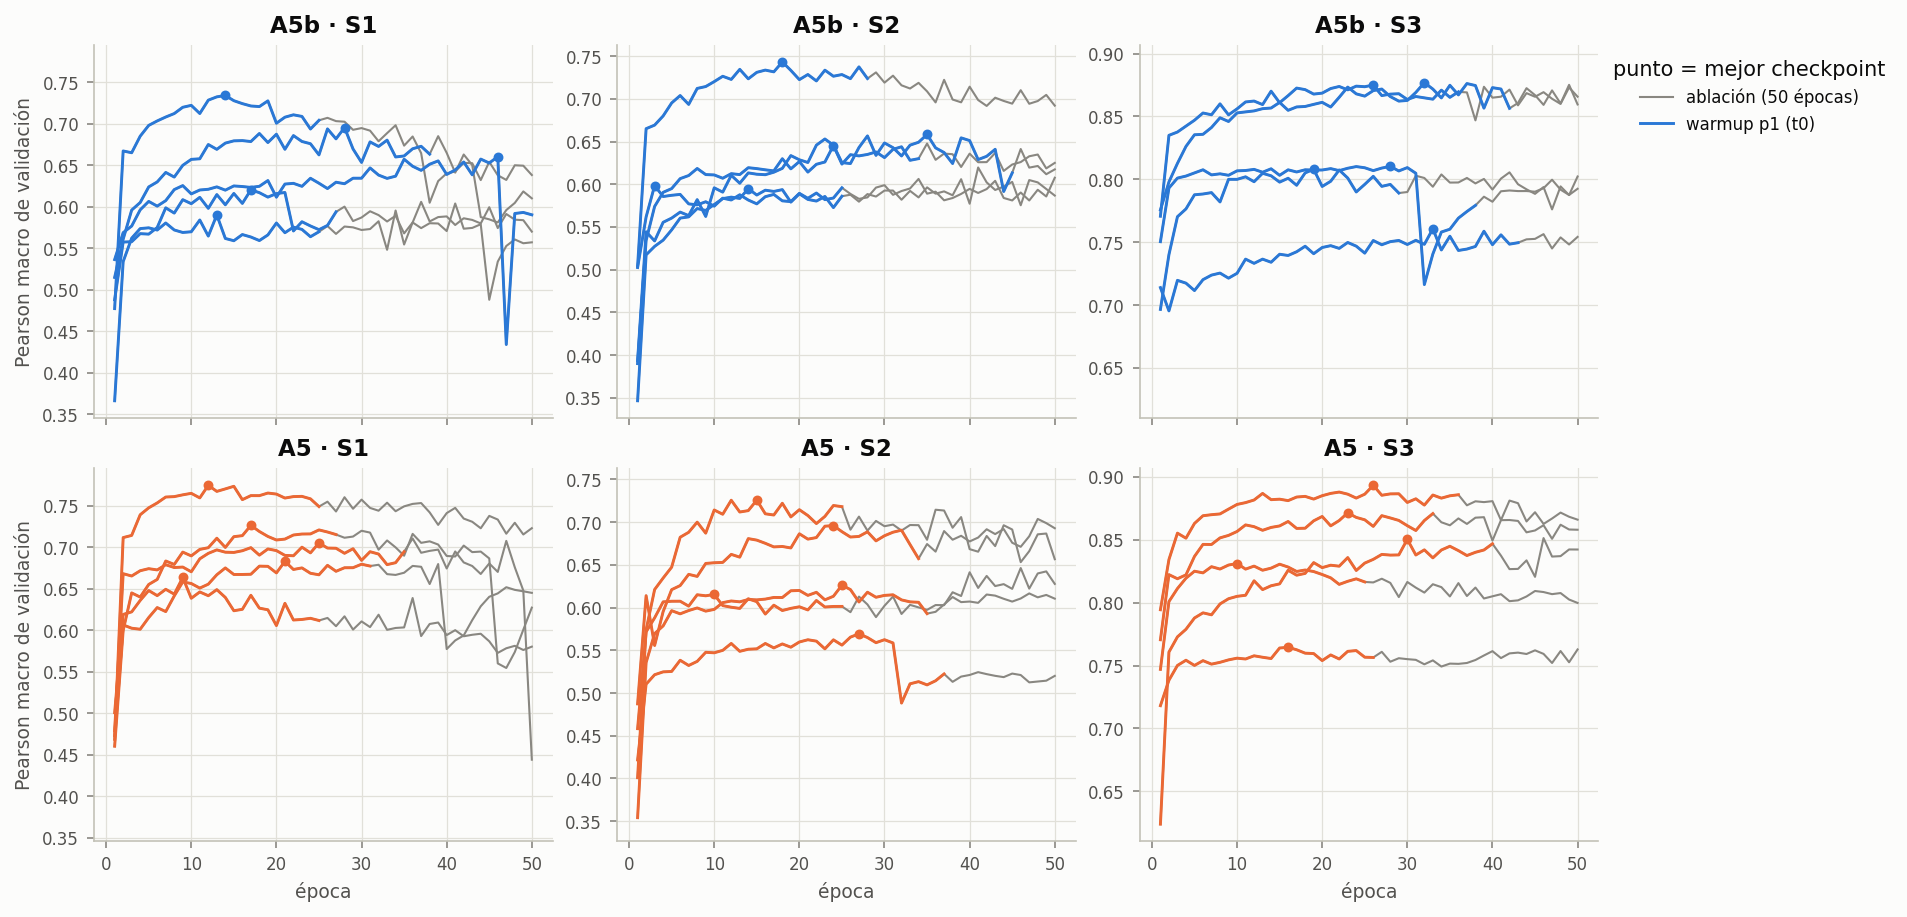

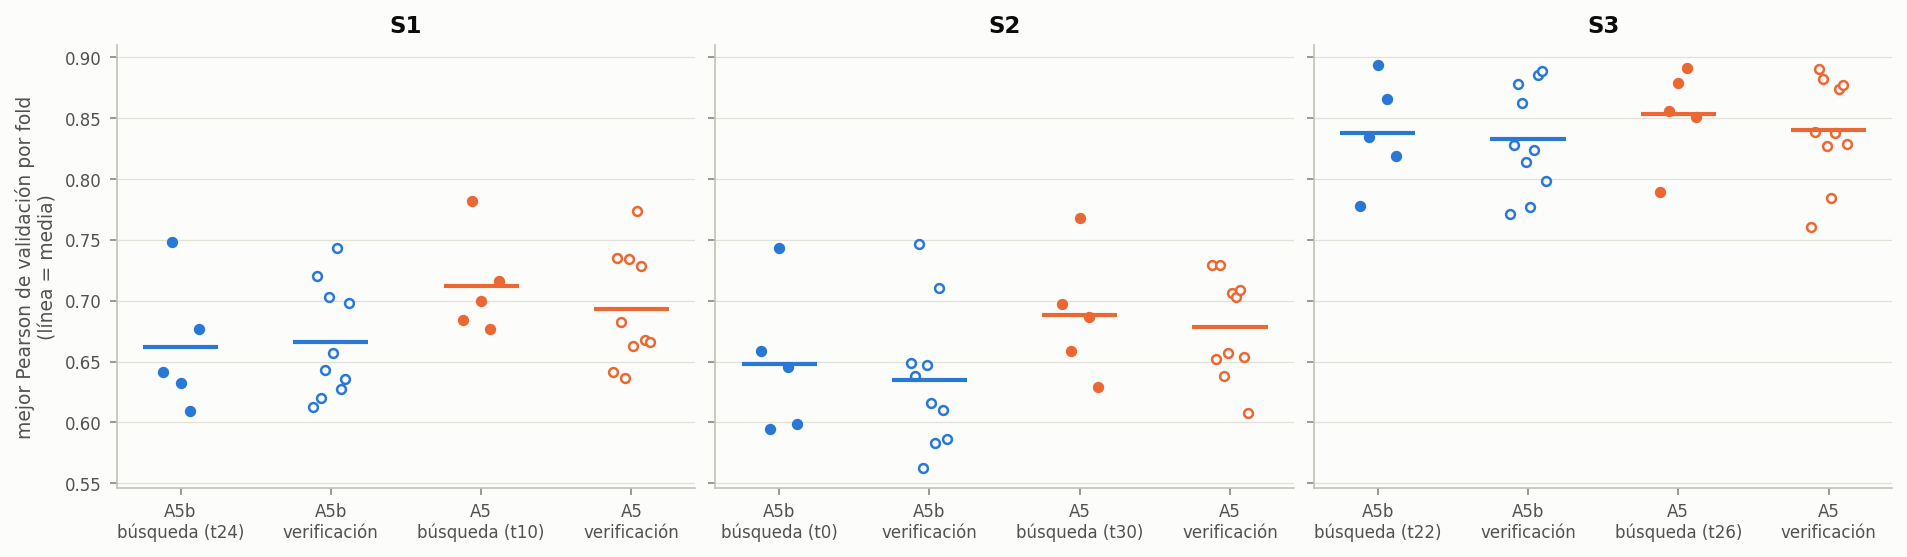

In [4]:
!cd "{REPO_DIR}" && python scripts/report_tpe.py --results-dir "{RESULTS_DIR}" 2>&1 | tail -40

import pandas as pd
from IPython.display import display
S = f"{RESULTS_DIR}/summary"
trials = pd.read_csv(f"{S}/tpe_trials.csv")
display(trials[trials.state == "COMPLETE"].sort_values("objective_cv_best", ascending=False)
        .groupby("subject").head(5)[["subject", "trial", "source", "label", "learning_rate", "weight_decay",
                                     "objective_cv_best", "mean_best_epoch", "mean_epochs_trained"]].round(5))
reporting.show_images([f"{S}/figures/{n}.png" for n in
                       ("optimization_history", "params_vs_objective", "reference_curves", "verification")])

## 12. Evaluación final en test
Una sola pasada por el test oficial, **después** de la verificación de cada sujeto. Nada de lo que salga aquí cambia decisiones: los finalistas y la elegida quedan fijados en `final_test/<S>/plan.json` antes de leer el test.

- **Modelos:** los dos finalistas de cada sujeto (mejor A5b y mejor A5) × 3 semillas (3042, 4042 y 5042, + 5·sujeto + 4), evaluados en su propio sujeto. El resultado principal es la elegida por la verificación (★); también se dan A5b frente a A5 y la media de cada arquitectura sobre los tres sujetos.
- **Entrenamiento:** B1–B4 con early stopping sobre B5 (misma política, **máximo 70 épocas**). El clip y los escaladores se ajustan solo con B1–B4. El test se predice una vez, con el mejor checkpoint.
- **Datos de test:** `test_data` sale de los `sub{n}_comp.mat` de `DATA_DIR`. Las etiquetas `sub1_testlabels.mat`, `sub2_testlabels.mat` y `sub3_testlabels.mat` hay que subirlas a **`Mi unidad/TPE_ECoG/test_labels/`** (`TEST_LABELS_DIR`). Se excluyen los mismos canales que en desarrollo (S1-54, S2-20, S2-37, S3-49; los tres últimos también están dañados en test).
- **Objetivo:** `test_dg` viene suavizado a 1000 Hz (no en escalones de 40 filas como `train_dg`), así que el objetivo es su valor en cada columna de 100 Hz. Se evalúan 197.5 s (1.25 s descartados en cada extremo).
- **Pesos:** estos modelos sí guardan `model.pt` (22–113 MB cada uno) y cada sujeto guarda `preprocessing.npz` (canales, clip y escaladores). `ecog_tpe.final_test.load_model` reconstruye el modelo.
- **Tiempo orientativo:** ≈ 20 min por sujeto (6 entrenamientos), ≈ 1 h los tres en serie. Se detiene con la sección 9; al relanzar esta celda se reanuda y la corrida en curso se repite.

In [4]:
import os, subprocess, sys, time
from ecog_tpe.runs import read_json

missing = [f"sub{n}_testlabels.mat" for n in (1, 2, 3) if not os.path.exists(f"{TEST_LABELS_DIR}/sub{n}_testlabels.mat")]
assert not missing, f"faltan en {TEST_LABELS_DIR}: {missing}"
ver = reporting.verification_table(RESULTS_DIR, CFG)
expected = 2 * len(CFG["verification"]["seed_bases"]) * len(CFG["folds"]["names"])
done = {s: int(((ver.subject == s) & (ver.state == "completed")).sum()) if not ver.empty else 0 for s in SUBJECTS}
assert all(n == expected for n in done.values()), f"verificación incompleta ({expected} corridas por sujeto): {done}"

LOG_PATH = f"{RESULTS_DIR}/logs/test_{'_'.join(SUBJECTS)}_{time.strftime('%Y%m%d_%H%M%S')}.log"
args = [sys.executable, "-u", f"{REPO_DIR}/scripts/run_tpe.py", "--subjects", *SUBJECTS, "--test",
        "--data-dir", DATA_DIR, "--test-labels-dir", TEST_LABELS_DIR, "--results-dir", RESULTS_DIR]
PROC = subprocess.Popen(args, stdout=open(LOG_PATH, "a"), stderr=subprocess.STDOUT, cwd=REPO_DIR,
                        start_new_session=True)
time.sleep(30)
print("PID", PROC.pid, "| estado:", "en marcha" if PROC.poll() is None else f"terminó (código {PROC.returncode})")
for s in SUBJECTS:
    plan = read_json(f"{RESULTS_DIR}/final_test/{s}/plan.json")
    if plan:
        print(s, "· elegida", plan["chosen"], "·", " · ".join(
            f"{a}: {f['label']} (t{f['trial']}, verificación {f['verification_cv_best']:.4f})"
            for a, f in plan["finalists"].items()))
print(open(LOG_PATH).read()[-2000:])

PID 2460 | estado: en marcha
S1 · elegida A5 · A5b: A5b k5 L5 f64 (t24, verificación 0.6660) · A5: A5 k5 L5 f64 (t10, verificación 0.6929)
2026-10-30 21:35:38 INFO NumExpr defaulting to 12 threads.
2026-10-30 21:35:44 INFO [S1] plan de test fijado: elegida A5 (A5b 0.6660, A5 0.6929)
2026-10-30 21:35:56 INFO [S1] fold B5 y test listos: 19750 columnas de test evaluadas, recorte en test 0.00e+00, máximo pico/típico en canales usados 3.6×
2026-10-30 21:36:05 INFO [S1 test A5b s3042] época 1/70  train 0.0650  val 0.0330  r_val 0.5176  mejor 0.5176 (ép. 1)  espera 0  (7.7 s)



In [ ]:
# Monitor del test, secciones 12 y 13 (reejecutable; detenerlo no detiene el entrenamiento)
reporting.monitor(RESULTS_DIR, CFG, SUBJECTS, refresh=10, final_test=True)

2026-10-30 22:34:19
runner 5aab059852bf-104772: último latido hace 52641 s · [S2 verif A5 s2042 B4]
runner 5cd20d5b8846-5513: último latido hace 99586 s · [S3 t000] B2
S1: 6/6 corridas · elegida A5 · test A5 0.6087 · A5b 0.5678
S2: 6/6 corridas · elegida A5 · test A5 0.5225 · A5b 0.4739
S3: 6/6 corridas · elegida A5 · test A5 0.7685 · A5b 0.7682
— últimas líneas de test_S1_S2_S3_20261030_213535.log —
2026-10-30 22:31:01 INFO [S3 test A5 s5042] época 22/70  train 0.0021  val 0.0240  r_val 0.8212  mejor 0.8284 (ép. 19)  espera 3  (3.6 s)
2026-10-30 22:31:05 INFO [S3 test A5 s5042] época 23/70  train 0.0020  val 0.0241  r_val 0.8246  mejor 0.8284 (ép. 19)  espera 4  (3.6 s)
2026-10-30 22:31:08 INFO [S3 test A5 s5042] época 24/70  train 0.0019  val 0.0234  r_val 0.8258  mejor 0.8284 (ép. 19)  espera 5  (3.6 s)
2026-10-30 22:31:12 INFO [S3 test A5 s5042] época 25/70  train 0.0018  val 0.0235  r_val 0.8246  mejor 0.8284 (ép. 19)  espera 6  (3.6 s)
2026-10-30 22:31:16 INFO [S3 test A5 s5042] 

: 

     S2                  A5            30       0.000052      0.000001            7               5            96        0.687830              0.678450              0.003940                 32                   True                A5b                    0.634821
     S3                  A5            26       0.000051      0.000002            7               5            64        0.853302              0.840189              0.000347                 28                   True                A5b                    0.832712

Test oficial (media ± sd de las semillas; en 'global', media y sd entre sujetos):
subject architecture_id  chosen         label  n_seeds  test_pearson_mean  test_pearson_sd  val_pearson_mean  verification_cv_best  mean_best_epoch
     S1             A5b   False A5b k5 L5 f64        3             0.5678           0.0146            0.7054                0.6660          35.0000
     S1              A5    True  A5 k5 L5 f64        3             0.6087           0.0175     

,subject,architecture_id,chosen,label,source_trial,n_seeds,test_pearson_mean,test_pearson_sd,val_pearson_mean,verification_cv_best,mean_best_epoch,mean_epochs_trained
0,S1,A5b,False,A5b k5 L5 f64,24.0,3,0.5678,0.0146,0.7054,0.6660,35.0000,45.0000
1,S1,A5,True,A5 k5 L5 f64,10.0,3,0.6087,0.0175,0.7280,0.6929,26.3333,36.3333
2,S2,A5b,False,A5b k5 L5 f64,0.0,3,0.4739,0.0101,0.5612,0.6348,23.3333,33.3333
3,S2,A5,True,A5 k7 L5 f96,30.0,3,0.5225,0.0319,0.6504,0.6785,33.6667,43.6667
4,S3,A5b,False,A5b k7 L5 f64,22.0,3,0.7682,0.0040,0.8152,0.8327,21.6667,31.6667
5,S3,A5,True,A5 k7 L5 f64,26.0,3,0.7685,0.0016,0.8392,0.8402,23.6667,33.6667
6,global,A5b,False,NaN,NaN,9,0.6033,0.1503,0.6939,0.7112,26.6667,36.6667
7,global,A5,False,NaN,NaN,9,0.6333,0.1248,0.7392,0.7372,27.8889,37.8889
8,global,elegida,True,NaN,NaN,9,0.6333,0.1248,0.7392,0.7372,27.8889,37.8889


seed_base                  3042    4042    5042
subject architecture_id                        
S1      A5               0.5914  0.6084  0.6263
        A5b              0.5754  0.5509  0.5770
S2      A5               0.5586  0.5109  0.4981
        A5b              0.4669  0.4856  0.4694
S3      A5               0.7683  0.7670  0.7702
        A5b              0.7703  0.7635  0.7707

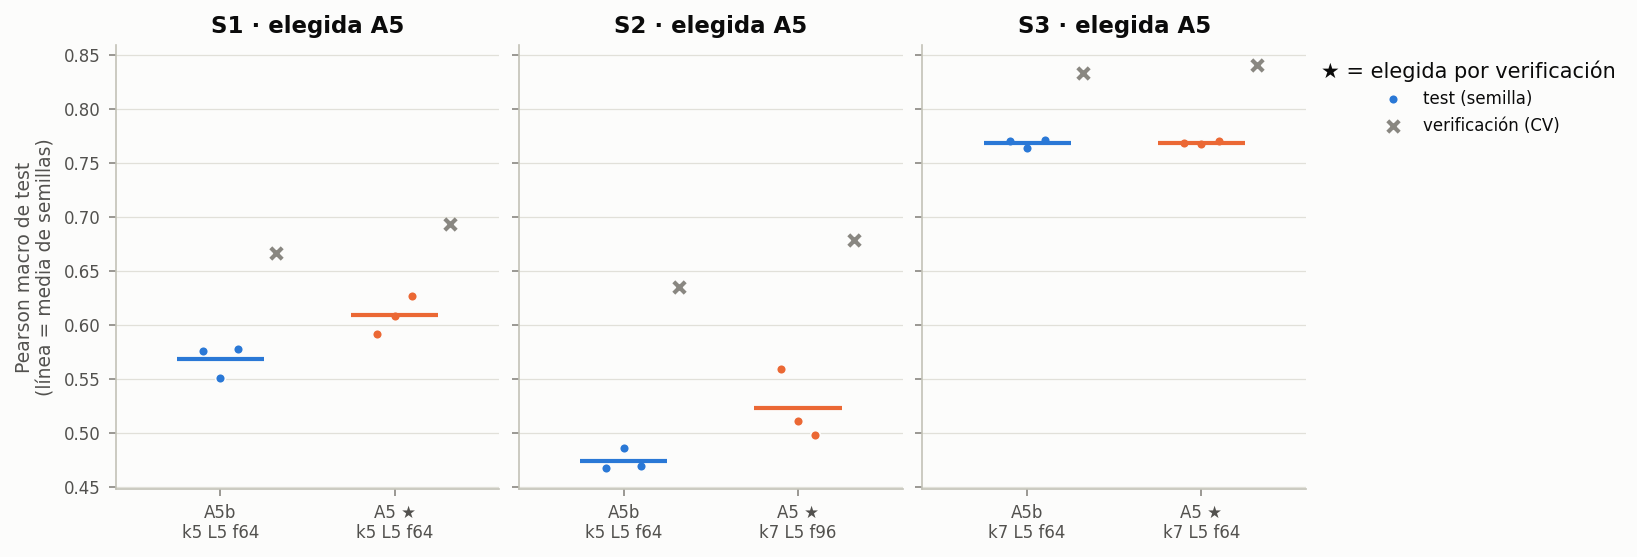

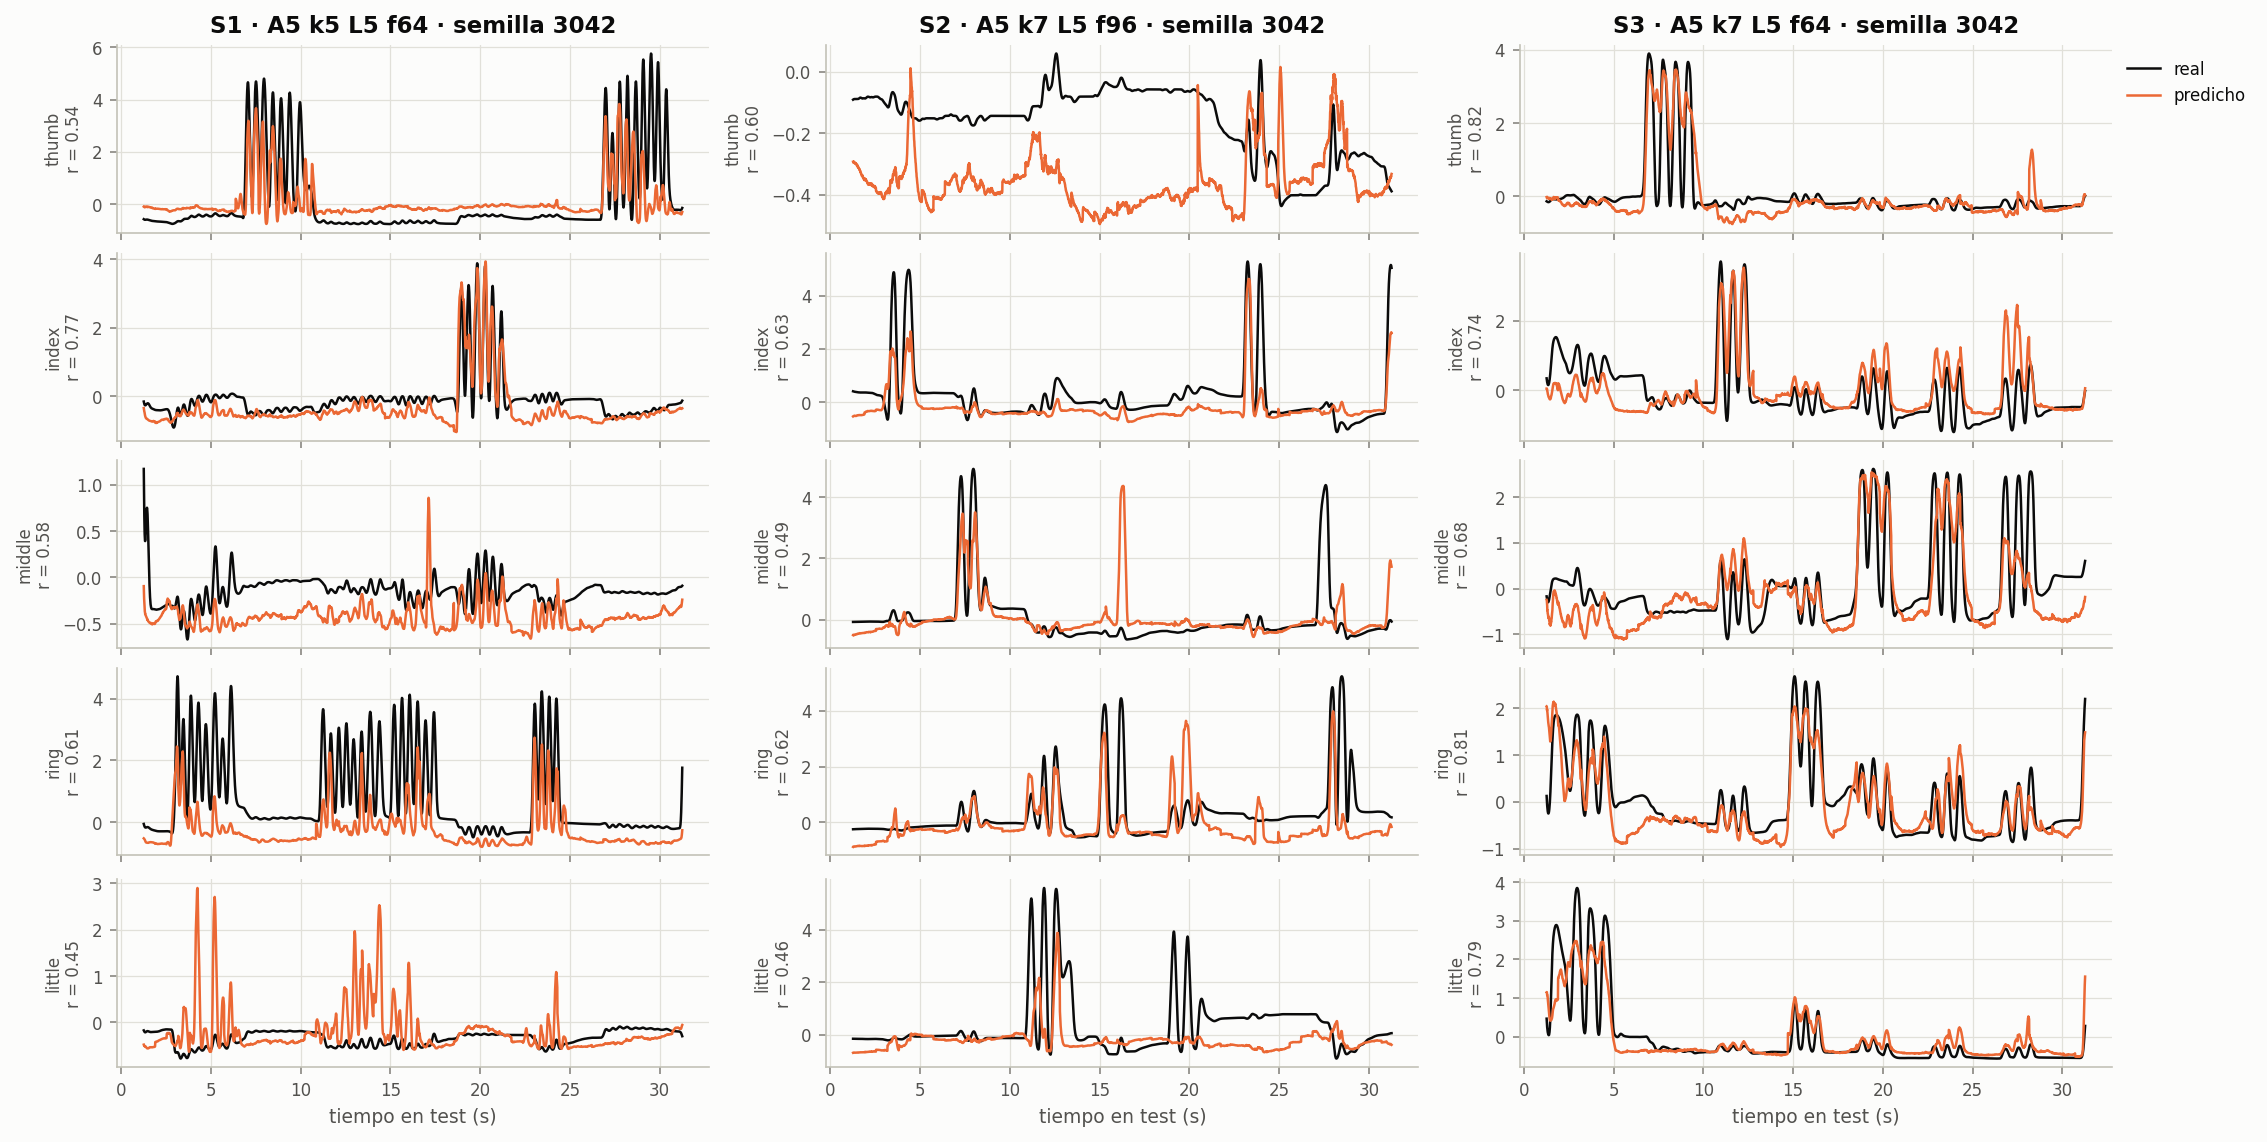

In [4]:
!cd "{REPO_DIR}" && python scripts/report_tpe.py --results-dir "{RESULTS_DIR}" 2>&1 | tail -14

import pandas as pd
from IPython.display import display
S = f"{RESULTS_DIR}/summary"
display(pd.read_csv(f"{S}/tpe_test_summary.csv").round(4))
test = pd.read_csv(f"{S}/tpe_test.csv")
if "test_pearson_macro" in test:  # Pearson macro de test por semilla
    display(test.pivot_table(index=["protocol", "subject", "architecture_id"], columns="seed_base",
                             values="test_pearson_macro").round(4))
reporting.show_images([f"{S}/figures/{n}.png" for n in ("test_scores", "test_trajectories")])

## 13. Test con B1–B5 (épocas fijas)
Segundo protocolo de test, aparte del de la sección 12: los mismos modelos entrenan con **los cinco bloques del desarrollo** (≈ 26 % más ventanas: 37 475 frente a 29 724). Así no queda bloque para el early stopping.

- **Épocas:** fijas por finalista, iguales a la mediana de sus 10 `best_epoch` de verificación (2 semillas × 5 folds), redondeada con medios hacia arriba (plan §7.1). Se evalúa el modelo de la **última** época. Esas corridas de verificación tenían un tope de 50 épocas.
- **Mismo número de épocas, no de pasos:** cada época tiene ≈ 26 % más lotes que en la sección 12.
- **Semillas:** las mismas que en la sección 12, con la misma inicialización. Cada modelo B1–B5 se compara apareado con su gemelo B1–B4 en `tpe_test_protocols.csv` (Δ = B1–B5 − B1–B4).
- **Plan:** `final_test_full/<S>/plan.json` (finalistas y elegida del plan de la sección 12, más las épocas), fijado antes de leer el test. El clip y los escaladores se ajustan con B1–B5; el test solo se transforma.
- **Requisitos:** solo la verificación completa, no la sección 12. Guarda `model.pt` y `preprocessing.npz`, como la sección 12.
- **Tiempo orientativo:** ≈ 1 h los tres sujetos en serie. El monitor está en la celda siguiente (el de la sección 12 muestra ambos protocolos). Se detiene con la sección 9.

In [ ]:
import os, subprocess, sys, time
from ecog_tpe.runs import read_json

missing = [f"sub{n}_testlabels.mat" for n in (1, 2, 3) if not os.path.exists(f"{TEST_LABELS_DIR}/sub{n}_testlabels.mat")]
assert not missing, f"faltan en {TEST_LABELS_DIR}: {missing}"
ver = reporting.verification_table(RESULTS_DIR, CFG)
expected = 2 * len(CFG["verification"]["seed_bases"]) * len(CFG["folds"]["names"])
done = {s: int(((ver.subject == s) & (ver.state == "completed")).sum()) if not ver.empty else 0 for s in SUBJECTS}
assert all(n == expected for n in done.values()), f"verificación incompleta ({expected} corridas por sujeto): {done}"

LOG_PATH = f"{RESULTS_DIR}/logs/test_full_{'_'.join(SUBJECTS)}_{time.strftime('%Y%m%d_%H%M%S')}.log"
args = [sys.executable, "-u", f"{REPO_DIR}/scripts/run_tpe.py", "--subjects", *SUBJECTS, "--test-full",
        "--data-dir", DATA_DIR, "--test-labels-dir", TEST_LABELS_DIR, "--results-dir", RESULTS_DIR]
PROC = subprocess.Popen(args, stdout=open(LOG_PATH, "a"), stderr=subprocess.STDOUT, cwd=REPO_DIR,
                        start_new_session=True)
time.sleep(30)
print("PID", PROC.pid, "| estado:", "en marcha" if PROC.poll() is None else f"terminó (código {PROC.returncode})")
for s in SUBJECTS:
    plan = read_json(f"{RESULTS_DIR}/final_test_full/{s}/plan.json")
    if plan:
        print(s, "· elegida", plan["chosen"], "·", " · ".join(
            f"{a}: {f['label']} → {f['epochs']} épocas (best_epoch de verificación {f['verification_best_epochs']})"
            for a, f in plan["finalists"].items()))
print(open(LOG_PATH).read()[-2000:])

In [ ]:
# Monitor del test con B1–B5 (reejecutable; detenerlo no detiene el entrenamiento)
reporting.monitor(RESULTS_DIR, CFG, SUBJECTS, refresh=30, final_test=True, protocols=["b1b5_fixed"])

In [ ]:
!cd "{REPO_DIR}" && python scripts/report_tpe.py --results-dir "{RESULTS_DIR}" 2>&1 | tail -10

import pandas as pd
from IPython.display import display
S = f"{RESULTS_DIR}/summary"
summary = pd.read_csv(f"{S}/tpe_test_summary.csv")
if not summary.empty:
    display(summary[summary.protocol == "b1b5_fixed"].round(4))
if os.path.getsize(f"{S}/tpe_test_protocols.csv") > 1:  # Δ = B1–B5 − B1–B4, apareado por semilla
    display(pd.read_csv(f"{S}/tpe_test_protocols.csv").round(4))
reporting.show_images([f"{S}/figures/{n}.png" for n in ("test_scores", "test_trajectories")])

## 14. Al terminar la sesión
Comprueba antes que no queda ningún runner vivo (sección 8) y después fuerza la sincronización de Drive antes de liberar el servidor (*Colab: Remove Server*).

In [5]:




try:
    drive.flush_and_unmount()
    print("Drive sincronizado y desmontado")
except Exception as exc:  # p. ej. si Drive se montó desde el comando de la extensión
    print("no se pudo desmontar Drive:", exc)

Drive sincronizado y desmontado
